# **Car Insurance Claim Risk Prediction: Abordagem Estatistica (GLM) / Statistical (GLM) Approach**

Comparativo de 5 modelos generalistas da familia GLM (Generalized Linear Models), em um `for`, implementando a abordagem estatistica descrita na "Parte 1 - Business Problem" de `model_ml.ipynb`. / Comparison of 5 generalist GLM models, in a `for` loop.

1. **Poisson** (link log)
2. **Binomial - Logit** (regressao logistica classica)
3. **Binomial - Probit**
4. **Binomial - Cloglog** (no lugar de Gamma, que exige resposta estritamente positiva e nao aceita o alvo 0/1)
5. **Binomial Negativa** (modelo de contagem, com alpha fixo em 1)

**Regras do projeto / Project rules**

- As variaveis com correlacao **positiva** com `is_claim` entram no modelo (com evidencia de que o sinal nao e ruido).
- **Nenhuma coluna nova e criada na base**: so selecionamos colunas existentes e codificamos as categoricas e as Sim/Nao em 0/1, sem olhar o alvo.
- **Sem vazamento**: a divisao treino/teste vem antes de qualquer decisao. Limites de outlier, correlacoes, categorias, escolha de variaveis e limiar de decisao vem so do treino; todas as escolhas sao feitas por validacao cruzada no treino, e o teste so e reportado.

**O que mudou em relacao a versao inicial / What changed**

- **`policy_tenure` entra como variavel nos 5 modelos.** E a variavel com maior correlacao positiva com o alvo, mas na versao inicial so o Poisson a usava (como offset); os outros 4 modelos nunca a viam.
- **`area_cluster` entra no lugar de `population_density`**, que e unica por cluster.
- **As 17 variaveis Sim/Nao do veiculo agora passam pela mesma regra das positivas**, e a selecao exige evidencia (correlacao acima de 2/raiz(n)), nao so o sinal.
- **As 5 familias usam o mesmo ponto de operacao** (mesma fracao de apolices marcadas), para as matrizes de confusao serem comparaveis.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    auc,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import OrdinalEncoder

PROJ_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
IMG, OUTPUT = PROJ_ROOT / "img", PROJ_ROOT / "output"
IMG.mkdir(exist_ok=True)
OUTPUT.mkdir(exist_ok=True)
pd.set_option("display.max_columns", None)

# **Parte 1 - Base bruta / Raw dataset**

Usamos `data/train.parquet` (bruta) e tratamos outliers dentro do notebook, so com estatisticas do treino. A versao `train_tratado_zscore.csv` calculou media e desvio com a base inteira, inclusive as linhas que viram teste. / We use the raw parquet and cap outliers with train-only statistics.

In [2]:
df = pd.read_parquet(PROJ_ROOT / "data" / "train.parquet")
TARGET = "is_claim"
y = df[TARGET]
print(df.shape, f"taxa de sinistro / claim rate = {y.mean():.4f}")

(58592, 44) taxa de sinistro / claim rate = 0.0640


# **Parte 2 - Divisao treino/teste antes de tudo / Train-test split before anything else**

In [3]:
idx_treino, idx_teste = train_test_split(np.arange(len(df)), test_size=0.2, random_state=42, stratify=y)
treino, teste = df.iloc[idx_treino].copy(), df.iloc[idx_teste].copy()
y_treino, y_teste = y.iloc[idx_treino].to_numpy(), y.iloc[idx_teste].to_numpy()
print(f"treino={treino.shape} teste={teste.shape} | sinistro treino={y_treino.mean():.4f} teste={y_teste.mean():.4f}")

treino=(46873, 44) teste=(11719, 44) | sinistro treino=0.0640 teste=0.0640


# **Parte 3 - Outliers com limites do treino / Outliers capped with train-only limits**

Mesma regra da analise exploratoria (limite em 3 desvios-padrao da media), com media e desvio so do treino. / Same EDA rule, train-only statistics.

In [4]:
COLUNAS_OUTLIER = ["age_of_car", "age_of_policyholder", "population_density"]
limites = {}
for c in COLUNAS_OUTLIER:
    media, desvio = treino[c].mean(), treino[c].std()
    limites[c] = (media - 3 * desvio, media + 3 * desvio)
    treino[c] = treino[c].clip(*limites[c])
    teste[c] = teste[c].clip(*limites[c])
pd.DataFrame(limites, index=["limite_inferior", "limite_superior"]).T.round(4)

,limite_inferior,limite_superior
age_of_car,-0.0998,0.2385
age_of_policyholder,0.1013,0.8381
population_density,-34153.4223,71812.4062


# **Parte 4 - Selecao de variaveis, so com o treino / Feature selection, train only**

**Correlacao com o alvo (X-Y) em todas as variaveis numericas e Sim/Nao.** As Sim/Nao sao lidas como 1/0 so dentro do calculo da correlacao (nada e gravado na base). As linhas tracejadas marcam `±2/raiz(n)`: abaixo disso, o sinal da correlacao nao se distingue de ruido. / X-Y correlation over every numeric and Yes/No column; Yes/No read as 1/0 inside the calculation only. Dashed lines mark ±2/sqrt(n).

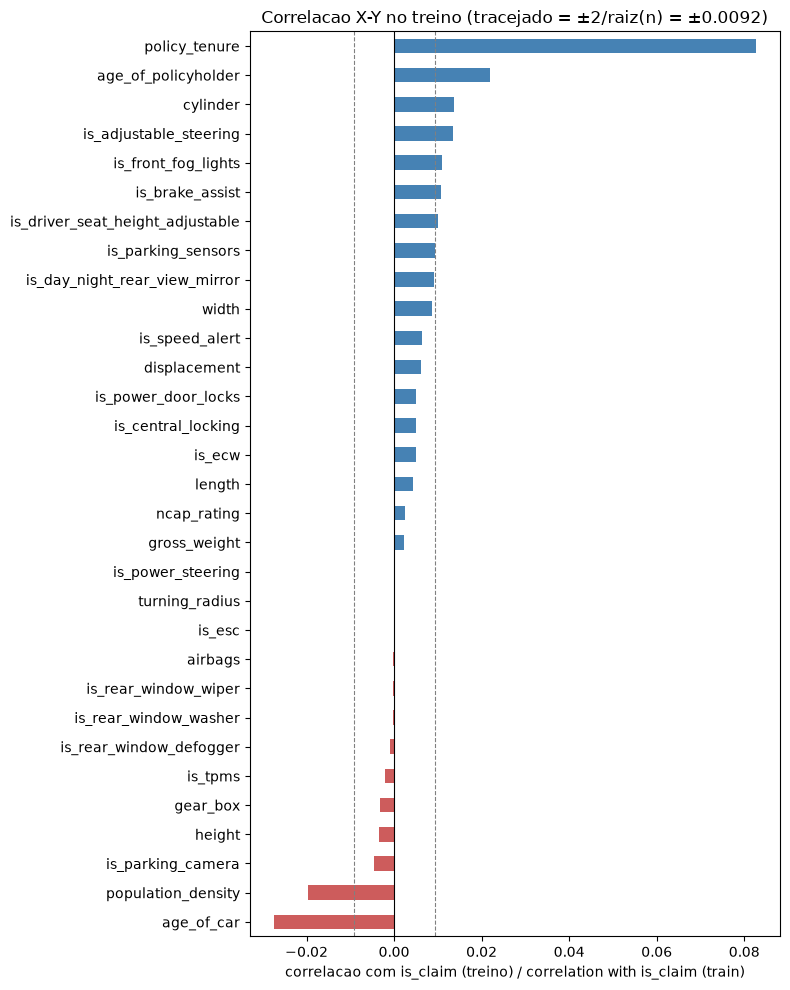

,corr_com_is_claim
policy_tenure,0.0827
age_of_policyholder,0.0219
cylinder,0.0136
is_adjustable_steering,0.0136
is_front_fog_lights,0.0110
is_brake_assist,0.0107
is_driver_seat_height_adjustable,0.0099
is_parking_sensors,0.0093
is_day_night_rear_view_mirror,0.0092
width,0.0087


In [5]:
POLICY_NUMERIC = ["policy_tenure", "age_of_car", "age_of_policyholder", "population_density"]
VEHICLE_NUMERIC = ["airbags", "displacement", "cylinder", "gear_box", "turning_radius", "length", "width", "height", "gross_weight", "ncap_rating"]
VEHICLE_SIM_NAO = [c for c in df.columns if c.startswith("is_") and c != TARGET]
VEICULO = VEHICLE_NUMERIC + VEHICLE_SIM_NAO


def como_numero(frame, colunas):
    """Visao numerica temporaria para correlacao: Sim/Nao -> 1/0. Nao altera a base."""
    return pd.DataFrame({c: (frame[c] == "Yes").astype(float) if c in VEHICLE_SIM_NAO else frame[c].astype(float) for c in colunas})


LIMIAR_EVIDENCIA = 2 / np.sqrt(len(treino))
corr_com_alvo = como_numero(treino, POLICY_NUMERIC + VEICULO).corrwith(pd.Series(y_treino, index=treino.index)).sort_values(ascending=False)

fig, eixo = plt.subplots(figsize=(8, 10))
corr_com_alvo.plot.barh(ax=eixo, color=["steelblue" if v > 0 else "indianred" for v in corr_com_alvo])
for x in (LIMIAR_EVIDENCIA, -LIMIAR_EVIDENCIA):
    eixo.axvline(x, color="gray", linestyle="--", linewidth=0.8)
eixo.axvline(0, color="black", linewidth=0.8)
eixo.invert_yaxis()
eixo.set_xlabel("correlacao com is_claim (treino) / correlation with is_claim (train)")
eixo.set_title(f"Correlacao X-Y no treino (tracejado = ±2/raiz(n) = ±{LIMIAR_EVIDENCIA:.4f})")
plt.tight_layout()
plt.savefig(IMG / "8output_glm_correlacao_alvo.png", dpi=120)
plt.show()

corr_com_alvo.round(4).to_frame("corr_com_is_claim")

**Colinearidade entre as variaveis do veiculo (X-X).** A base tem so 11 valores de `model`, e as especificacoes do carro andam juntas (varios pares acima de 0,85). / The dataset has only 11 `model` values and car specs move together.

valores unicos de model no treino: 11


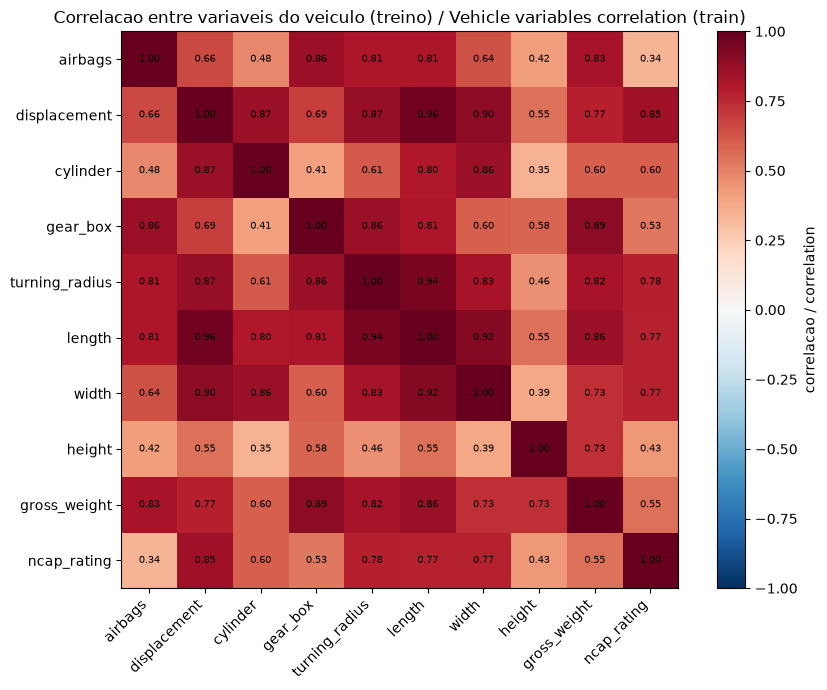

In [6]:
print("valores unicos de model no treino:", treino["model"].nunique())

corr_veiculo = treino[VEHICLE_NUMERIC].corr()
fig, eixo = plt.subplots(figsize=(9, 7))
cax = eixo.imshow(corr_veiculo, cmap="RdBu_r", vmin=-1, vmax=1)
eixo.set_xticks(range(len(VEHICLE_NUMERIC)))
eixo.set_xticklabels(VEHICLE_NUMERIC, rotation=45, ha="right")
eixo.set_yticks(range(len(VEHICLE_NUMERIC)))
eixo.set_yticklabels(VEHICLE_NUMERIC)
for i in range(len(VEHICLE_NUMERIC)):
    for j in range(len(VEHICLE_NUMERIC)):
        eixo.text(j, i, f"{corr_veiculo.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(cax, label="correlacao / correlation")
eixo.set_title("Correlacao entre variaveis do veiculo (treino) / Vehicle variables correlation (train)")
plt.tight_layout()
plt.savefig(IMG / "7output_glm_correlacao_veiculo.png", dpi=120)
plt.show()

**Regra de selecao das variaveis do veiculo / Vehicle variable selection rule**

1. Candidatas: correlacao positiva com o alvo **acima de 2/raiz(n)** (sinal com evidencia, nao ruido).
2. Entre as candidatas, a cada rodada sai a que tem mais pares com `|r| >= 0,80` (empate desfeito pela correlacao mais fraca com o alvo).
3. Como todo atributo do carro e funcao do `model`, cada sobrevivente so entra se aumentar o posto da matriz de design (ja com `segment`, `transmission_type` e `area_cluster`) — se nao acrescenta informacao nova, nao entra.

In [7]:
CATEGORICAS_BASE = ["segment", "transmission_type", "area_cluster"]
NIVEIS = {c: sorted(treino[c].astype(str).unique()) for c in CATEGORICAS_BASE + VEHICLE_SIM_NAO}


def matriz(frame, numericas, categoricas):
    partes = [frame[numericas].astype(float).reset_index(drop=True)]
    for c in categoricas:
        valores = frame[c].astype(str)
        valores = valores.where(valores.isin(NIVEIS[c]))  # nivel nunca visto no treino -> categoria de referencia
        partes.append(pd.get_dummies(pd.Categorical(valores, categories=NIVEIS[c]), prefix=c, drop_first=True, dtype=float))
    return sm.add_constant(pd.concat(partes, axis=1), has_constant="add")


posto = lambda X: np.linalg.matrix_rank(X.to_numpy())

candidatas = [c for c in corr_com_alvo.index if c in VEICULO and corr_com_alvo[c] > LIMIAR_EVIDENCIA]
print("1) candidatas (positivas com evidencia):", candidatas)

LIMIAR_COLINEARIDADE = 0.80
sobreviventes, removidas_colinearidade = candidatas.copy(), []
while len(sobreviventes) > 1:
    sub = como_numero(treino, sobreviventes).corr().abs().to_numpy().copy()
    np.fill_diagonal(sub, 0.0)
    conexoes = pd.Series((sub >= LIMIAR_COLINEARIDADE).sum(axis=0), index=sobreviventes)
    if conexoes.max() == 0:
        break
    pior = corr_com_alvo[conexoes[conexoes == conexoes.max()].index].idxmin()
    removidas_colinearidade.append(pior)
    sobreviventes.remove(pior)
print("2) removidas por colinearidade |r| >= 0,80:", removidas_colinearidade)

POLICY_FINAL = ["policy_tenure", "age_of_car", "age_of_policyholder"]
veiculo_numericas, veiculo_sim_nao, sem_informacao_nova = [], [], []
posto_atual = posto(matriz(treino, POLICY_FINAL, CATEGORICAS_BASE))
for c in sobreviventes:
    num_teste = veiculo_numericas + ([c] if c in VEHICLE_NUMERIC else [])
    cat_teste = veiculo_sim_nao + ([c] if c in VEHICLE_SIM_NAO else [])
    novo_posto = posto(matriz(treino, POLICY_FINAL + num_teste, CATEGORICAS_BASE + cat_teste))
    if novo_posto > posto_atual:
        veiculo_numericas, veiculo_sim_nao, posto_atual = num_teste, cat_teste, novo_posto
    else:
        sem_informacao_nova.append(c)
print("3) sem informacao nova alem de segment/transmission/area:", sem_informacao_nova)
print("variaveis do veiculo que entram:", veiculo_numericas + veiculo_sim_nao)

1) candidatas (positivas com evidencia): ['cylinder', 'is_adjustable_steering', 'is_front_fog_lights', 'is_brake_assist', 'is_driver_seat_height_adjustable', 'is_parking_sensors']
2) removidas por colinearidade |r| >= 0,80: ['is_driver_seat_height_adjustable', 'is_brake_assist', 'is_front_fog_lights', 'is_adjustable_steering']
3) sem informacao nova alem de segment/transmission/area: []
variaveis do veiculo que entram: ['cylinder', 'is_parking_sensors']


**Variaveis finais / Final variables**

- `policy_tenure` e `age_of_policyholder`: correlacao positiva com o alvo, com folga sobre o limiar de evidencia — entram.
- Variaveis do veiculo: as que passaram pelos 3 passos acima.
- `age_of_car`: correlacao **negativa**, mas e o 2º sinal mais forte da base. Fica: na Parte 10, remove-la derruba o ROC-AUC na validacao cruzada.
- `population_density`: sai, porque e unica por `area_cluster` (colinear com as dummies de cluster).
- Categoricas `segment`, `transmission_type`, `area_cluster` e as Sim/Nao escolhidas: codificadas em 0/1 com as categorias vistas no treino.

In [8]:
assert treino.groupby("area_cluster")["population_density"].nunique().max() == 1, "density deixou de ser unica por cluster"

NUMERICAS = POLICY_FINAL + veiculo_numericas
CATEGORICAS = CATEGORICAS_BASE + veiculo_sim_nao

X_treino, X_teste = matriz(treino, NUMERICAS, CATEGORICAS), matriz(teste, NUMERICAS, CATEGORICAS)
assert posto(X_treino) == X_treino.shape[1], "matriz de design sem posto completo"
nao_vistos = {c: int((~teste[c].astype(str).isin(NIVEIS[c])).sum()) for c in CATEGORICAS}
print("numericas:", NUMERICAS)
print("categoricas:", CATEGORICAS)
print("matriz de design:", X_treino.shape, "(posto completo) | linhas do teste com categoria nunca vista no treino:", nao_vistos)

numericas: ['policy_tenure', 'age_of_car', 'age_of_policyholder', 'cylinder']
categoricas: ['segment', 'transmission_type', 'area_cluster', 'is_parking_sensors']
matriz de design: (46873, 33) (posto completo) | linhas do teste com categoria nunca vista no treino: {'segment': 0, 'transmission_type': 0, 'area_cluster': 0, 'is_parking_sensors': 0}


# **Parte 5 - Os 5 modelos GLM, em for / The 5 GLM models, in a for loop**

Para cada modelo: validacao cruzada 5-fold **dentro do treino** (estimativa estavel de ROC-AUC e previsoes fora-da-amostra), ajuste final no treino inteiro e previsao no teste. / For each model: 5-fold CV inside the training set, final fit on the full training set, prediction on the test set.

In [9]:
FAMILIAS = {
    "Poisson": sm.families.Poisson(),
    "Binomial - Logit": sm.families.Binomial(),
    "Binomial - Probit": sm.families.Binomial(link=sm.families.links.Probit()),
    "Binomial - Cloglog": sm.families.Binomial(link=sm.families.links.CLogLog()),
    "Binomial Negativa": sm.families.NegativeBinomial(alpha=1.0),
}

DOBRAS = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(treino, y_treino))


def validacao_cruzada(familia, numericas, categoricas, offset=False):
    """Previsoes fora-da-amostra no treino + ROC-AUC/PR-AUC medios das 5 dobras."""
    oof = np.zeros(len(treino))
    rocs, prs = [], []
    for a, b in DOBRAS:
        off_a = np.log(treino["policy_tenure"].iloc[a].to_numpy()) if offset else None
        off_b = np.log(treino["policy_tenure"].iloc[b].to_numpy()) if offset else None
        ajuste = sm.GLM(y_treino[a], matriz(treino.iloc[a], numericas, categoricas), family=familia, offset=off_a).fit()
        oof[b] = np.asarray(ajuste.predict(matriz(treino.iloc[b], numericas, categoricas), offset=off_b))
        rocs.append(roc_auc_score(y_treino[b], oof[b]))
        prs.append(average_precision_score(y_treino[b], oof[b]))
    return oof, float(np.mean(rocs)), float(np.std(rocs)), float(np.mean(prs))


modelos, oofs, probas_teste, cv = {}, {}, {}, {}
for nome, familia in FAMILIAS.items():
    oofs[nome], cv_roc, cv_dp, cv_pr = validacao_cruzada(familia, NUMERICAS, CATEGORICAS)
    cv[nome] = {"cv_roc_auc": cv_roc, "cv_roc_auc_dp": cv_dp, "cv_pr_auc": cv_pr}
    modelos[nome] = sm.GLM(y_treino, X_treino, family=familia).fit()
    probas_teste[nome] = np.asarray(modelos[nome].predict(X_teste))
    print(f"{nome:20s} CV ROC-AUC = {cv_roc:.4f} ± {cv_dp:.4f} | teste ROC-AUC = {roc_auc_score(y_teste, probas_teste[nome]):.4f}")

Poisson              CV ROC-AUC = 0.6104 ± 0.0064 | teste ROC-AUC = 0.5857


Binomial - Logit     CV ROC-AUC = 0.6104 ± 0.0064 | teste ROC-AUC = 0.5857


Binomial - Probit    CV ROC-AUC = 0.6106 ± 0.0065 | teste ROC-AUC = 0.5857


Binomial - Cloglog   CV ROC-AUC = 0.6104 ± 0.0063 | teste ROC-AUC = 0.5857


Binomial Negativa    CV ROC-AUC = 0.6104 ± 0.0064 | teste ROC-AUC = 0.5856


# **Parte 6 - Ponto de operacao comum / Common operating point**

O limiar de Youden (maximo de acuracia balanceada) cai numa curva muito plana: cortes bem diferentes dao praticamente a mesma acuracia balanceada, e cada familia acabava num corte diferente por acaso. Por isso escolhemos **uma unica fracao de apolices marcadas** (passos de 5%), a que maximiza a acuracia balanceada media das 5 familias nas previsoes fora-da-amostra do treino, e aplicamos a mesma fracao a todas. / Youden's curve is flat; we pick one flagged share (5% steps) maximizing mean out-of-fold balanced accuracy across the 5 families and apply it to all.

In [10]:
GRADE = np.round(np.arange(0.10, 0.65, 0.05), 2)
bal_por_fracao = pd.DataFrame(
    {nome: [balanced_accuracy_score(y_treino, (oofs[nome] >= np.quantile(oofs[nome], 1 - f)).astype(int)) for f in GRADE] for nome in FAMILIAS},
    index=pd.Index(GRADE, name="fracao_marcada"),
)
bal_por_fracao["media"] = bal_por_fracao.mean(axis=1)
FRACAO = float(bal_por_fracao["media"].idxmax())
limiares = {nome: float(np.quantile(oofs[nome], 1 - FRACAO)) for nome in FAMILIAS}
print(f"fracao escolhida: {FRACAO:.0%} das apolices")
bal_por_fracao.round(4)

fracao escolhida: 45% das apolices


,Poisson,Binomial - Logit,Binomial - Probit,Binomial - Cloglog,Binomial Negativa,media
fracao_marcada,,,,,,
0.10,0.5319,0.5323,0.5316,0.5325,0.5317,0.5320
0.15,0.5417,0.5417,0.5419,0.5419,0.5416,0.5418
0.20,0.5526,0.5528,0.5532,0.5528,0.5526,0.5528
0.25,0.5617,0.5614,0.5614,0.5617,0.5616,0.5616
0.30,0.5703,0.5705,0.5707,0.5703,0.5701,0.5704
0.35,0.5723,0.5725,0.5726,0.5725,0.5719,0.5724
0.40,0.5785,0.5784,0.5784,0.5785,0.5785,0.5785
0.45,0.5810,0.5810,0.5818,0.5814,0.5809,0.5812
0.50,0.5805,0.5807,0.5809,0.5807,0.5807,0.5807


# **Parte 7 - Tabela comparativa (teste) / Comparison table (test set)**

`sinalizadas` = fracao das apolices marcadas no teste; `lift` = precisao / taxa base de sinistro. As 5 familias aparecem na ordem fixa da lista, sem ranking: a diferenca entre elas fica na 4a casa decimal. / Fixed order, no ranking: the families differ only in the 4th decimal.

In [11]:
resultados = []
for nome in FAMILIAS:
    proba = probas_teste[nome]
    pred = (proba >= limiares[nome]).astype(int)
    resultados.append({
        "modelo": nome,
        "roc_auc": roc_auc_score(y_teste, proba),
        "pr_auc": average_precision_score(y_teste, proba),
        "acuracia": accuracy_score(y_teste, pred),
        "acuracia_balanceada": balanced_accuracy_score(y_teste, pred),
        "recall": recall_score(y_teste, pred, zero_division=0),
        "precisao": precision_score(y_teste, pred, zero_division=0),
        "f1": f1_score(y_teste, pred, zero_division=0),
        "brier": brier_score_loss(y_teste, proba),
        "aic": modelos[nome].aic,
        "limiar": limiares[nome],
        "sinalizadas": pred.mean(),
        **cv[nome],
    })
tabela_glm = pd.DataFrame(resultados)
tabela_glm["lift"] = tabela_glm["precisao"] / y_teste.mean()
tabela_glm.round(4)

,modelo,roc_auc,pr_auc,acuracia,acuracia_balanceada,recall,precisao,f1,brier,aic,limiar,sinalizadas,cv_roc_auc,cv_roc_auc_dp,cv_pr_auc,lift
0,Poisson,0.5857,0.0863,0.5668,0.5599,0.5520,0.0803,0.1402,0.0596,22078.8432,0.0632,0.4399,0.6104,0.0064,0.0907,1.2549
1,Binomial - Logit,0.5857,0.0864,0.5663,0.5597,0.5520,0.0802,0.1401,0.0596,21849.8912,0.0635,0.4403,0.6104,0.0064,0.0907,1.2537
2,Binomial - Probit,0.5857,0.0862,0.5664,0.5585,0.5493,0.0799,0.1395,0.0596,21845.0781,0.0642,0.4399,0.6106,0.0065,0.0907,1.2488
3,Binomial - Cloglog,0.5857,0.0863,0.5667,0.5598,0.5520,0.0803,0.1402,0.0596,21850.9857,0.0633,0.4400,0.6104,0.0063,0.0906,1.2546
4,Binomial Negativa,0.5856,0.0863,0.5665,0.5598,0.5520,0.0803,0.1401,0.0596,22293.5613,0.0632,0.4401,0.6104,0.0064,0.0907,1.2541


# **Parte 8 - Incidence Rate Ratios (IRR) do Poisson / Poisson IRR**

So as variaveis de apolice/segurado e de regiao sao interpretaveis uma a uma. Os coeficientes do bloco do veiculo (`segment`, `transmission_type` e as variaveis do carro escolhidas) so sao identificados em conjunto, pelos 11 modelos de carro: um IRR isolado ali e artefato de colinearidade. Por isso o bloco do veiculo aparece como um unico teste conjunto. `irr_na_faixa_observada` = efeito do menor ao maior valor visto no treino (as variaveis continuas estao em escala normalizada, entao "por unidade" pode extrapolar). / Only policy and region variables are interpretable one by one; the vehicle block is tested jointly.

In [12]:
poisson_fit = modelos["Poisson"]
interpretaveis = [c for c in poisson_fit.params.index if c in POLICY_FINAL or c.startswith("area_cluster_")]
bloco_veiculo = [c for c in poisson_fit.params.index if c not in interpretaveis and c != "const"]

irr = pd.DataFrame({
    "coeficiente": poisson_fit.params[interpretaveis],
    "irr": np.exp(poisson_fit.params[interpretaveis]),
    "irr_ic_inferior": np.exp(poisson_fit.conf_int().loc[interpretaveis, 0]),
    "irr_ic_superior": np.exp(poisson_fit.conf_int().loc[interpretaveis, 1]),
    "p_valor": poisson_fit.pvalues[interpretaveis],
})
faixa = {c: treino[c].max() - treino[c].min() for c in POLICY_FINAL}
irr["irr_na_faixa_observada"] = [np.exp(poisson_fit.params[c] * faixa[c]) if c in faixa else np.nan for c in irr.index]

restricao = np.eye(len(poisson_fit.params))[[poisson_fit.params.index.get_loc(c) for c in bloco_veiculo]]
wald = poisson_fit.wald_test(restricao, scalar=True)
print("categorias de referencia:", {c: NIVEIS[c][0] for c in CATEGORICAS})
print(f"bloco do veiculo ({len(bloco_veiculo)} coeficientes): teste de Wald conjunto p = {float(wald.pvalue):.4g}")
irr.sort_values("irr", ascending=False).round(4)

categorias de referencia: {'segment': 'A', 'transmission_type': 'Automatic', 'area_cluster': 'C1', 'is_parking_sensors': 'No'}
bloco do veiculo (8 coeficientes): teste de Wald conjunto p = 0.0545


,coeficiente,irr,irr_ic_inferior,irr_ic_superior,p_valor,irr_na_faixa_observada
policy_tenure,0.8236,2.2787,2.0695,2.5091,0.0000,3.1521
area_cluster_C18,0.7806,2.1828,1.3370,3.5636,0.0018,NaN
area_cluster_C21,0.4949,1.6403,1.0335,2.6034,0.0358,NaN
area_cluster_C4,0.4074,1.5029,1.0058,2.2458,0.0468,NaN
area_cluster_C3,0.3659,1.4418,1.0949,1.8986,0.0092,NaN
area_cluster_C2,0.2629,1.3006,0.9885,1.7113,0.0605,NaN
area_cluster_C14,0.2351,1.2650,0.9462,1.6913,0.1125,NaN
area_cluster_C19,0.2263,1.2539,0.8682,1.8110,0.2277,NaN
age_of_policyholder,0.2198,1.2459,0.9312,1.6668,0.1389,1.1284
area_cluster_C8,0.1963,1.2169,0.9298,1.5928,0.1528,NaN


# **Parte 9 - Curva ROC, matrizes de confusao e trade-off do limiar (teste) / ROC, confusion matrices and threshold trade-off (test)**

As matrizes usam a fracao comum escolhida na Parte 6. A linha de baixo e normalizada pela classe real: le-se "% dos sinistros reais que o modelo pega" e "% das apolices sem sinistro que ele libera". / Matrices use the common share from Part 6; the bottom row is normalized by the true class.

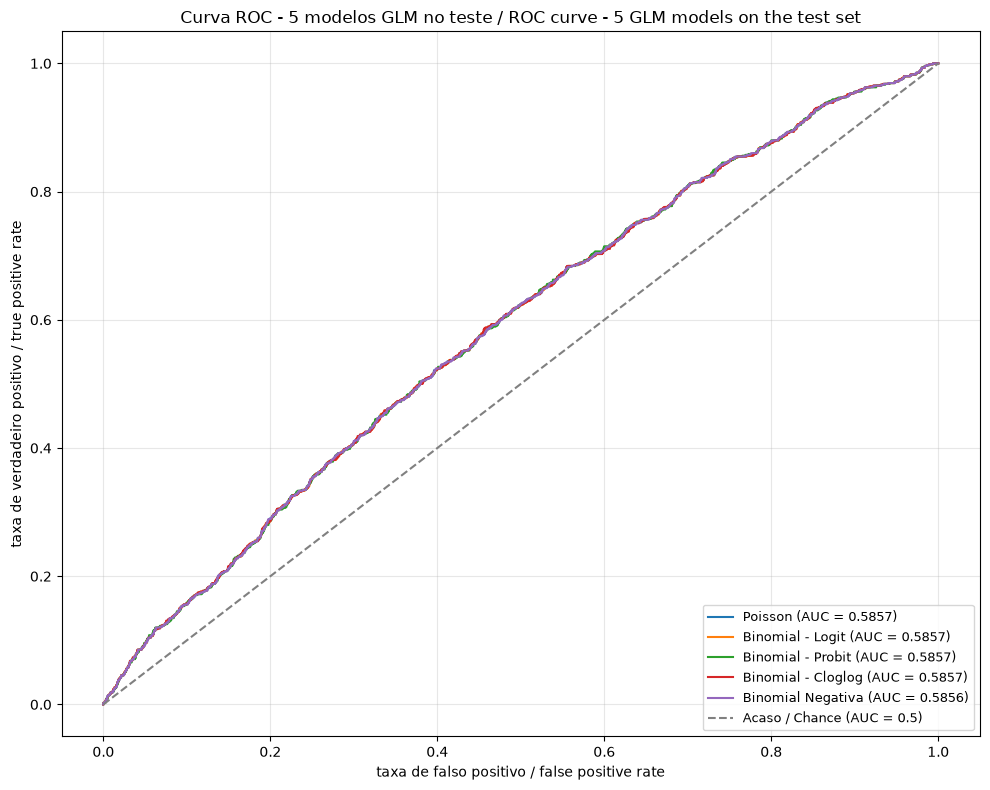

In [13]:
fig, eixo = plt.subplots(figsize=(10, 8))
for nome, proba in probas_teste.items():
    fpr, tpr, _ = roc_curve(y_teste, proba)
    eixo.plot(fpr, tpr, linewidth=1.5, label=f"{nome} (AUC = {auc(fpr, tpr):.4f})")
eixo.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Acaso / Chance (AUC = 0.5)")
eixo.set_xlabel("taxa de falso positivo / false positive rate")
eixo.set_ylabel("taxa de verdadeiro positivo / true positive rate")
eixo.set_title("Curva ROC - 5 modelos GLM no teste / ROC curve - 5 GLM models on the test set")
eixo.legend(loc="lower right", fontsize=9)
eixo.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(IMG / "9output_glm_roc.png", dpi=120)
plt.show()

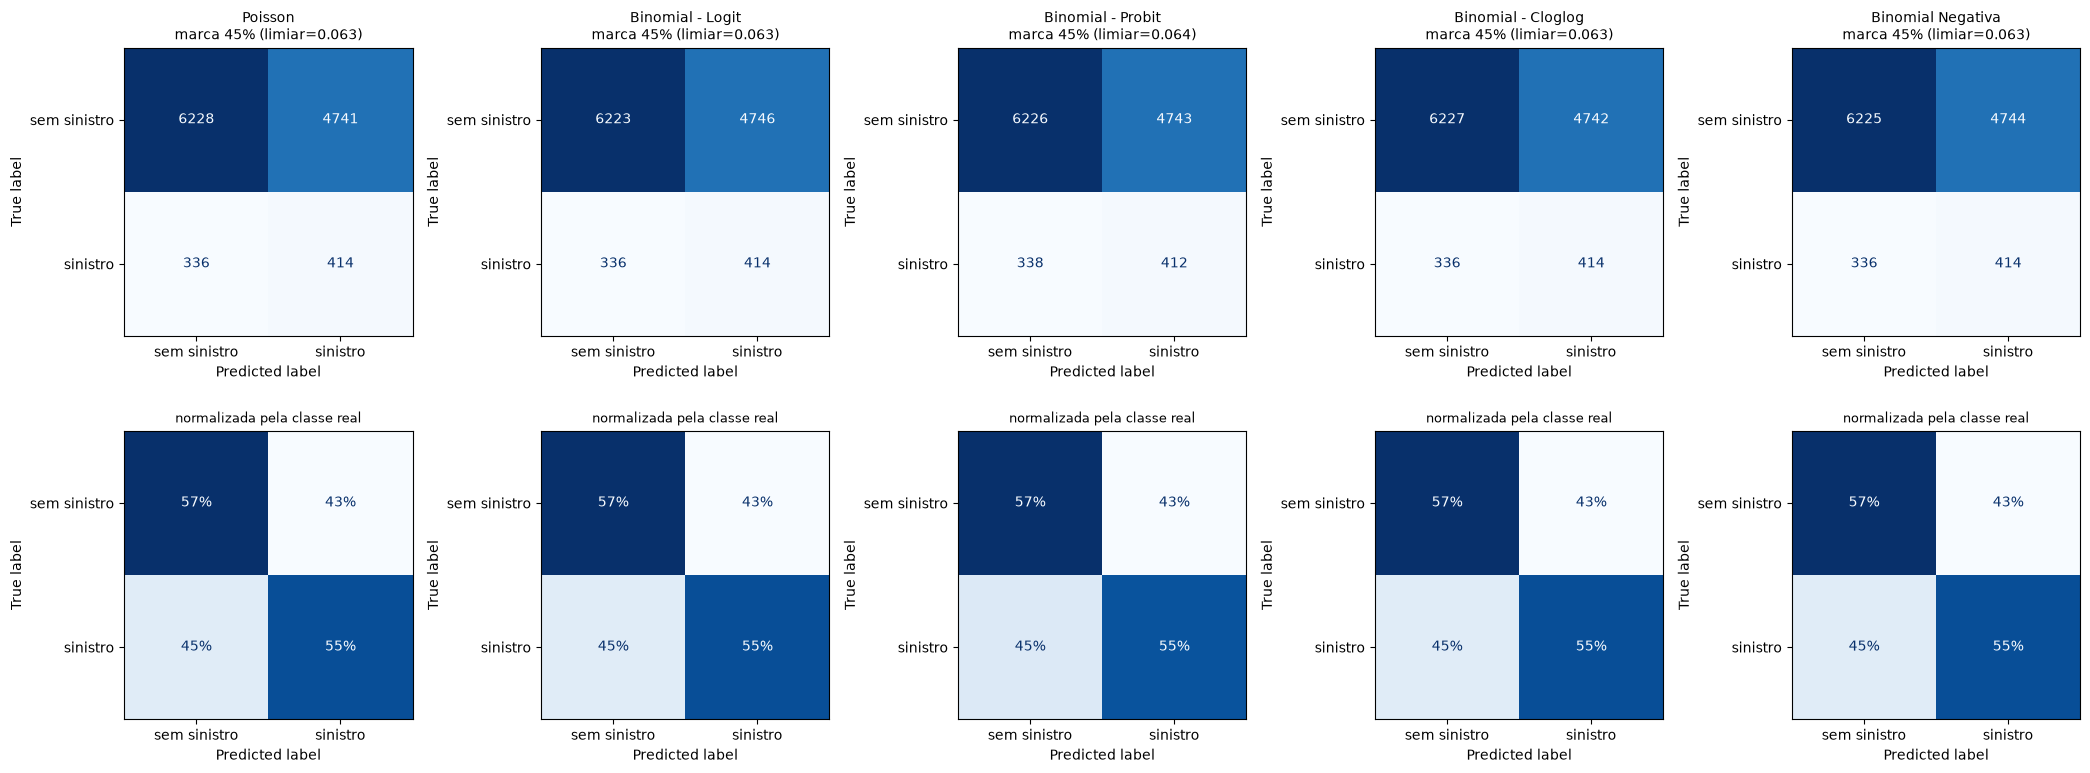

In [14]:
fig, eixos = plt.subplots(2, len(probas_teste), figsize=(4.2 * len(probas_teste), 8))
for j, (nome, proba) in enumerate(probas_teste.items()):
    pred = (proba >= limiares[nome]).astype(int)
    ConfusionMatrixDisplay(confusion_matrix(y_teste, pred), display_labels=["sem sinistro", "sinistro"]).plot(
        ax=eixos[0, j], cmap="Blues", colorbar=False, values_format="d"
    )
    ConfusionMatrixDisplay(confusion_matrix(y_teste, pred, normalize="true"), display_labels=["sem sinistro", "sinistro"]).plot(
        ax=eixos[1, j], cmap="Blues", colorbar=False, values_format=".0%"
    )
    eixos[0, j].set_title(f"{nome}\nmarca {FRACAO:.0%} (limiar={limiares[nome]:.3f})", fontsize=10)
    eixos[1, j].set_title("normalizada pela classe real", fontsize=9)
plt.tight_layout()
plt.savefig(IMG / "10output_glm_confusion.png", dpi=120)
plt.show()

**O limiar e uma decisao de negocio / The threshold is a business decision.** Marcar mais apolices pega mais sinistros, ao custo de mais falsos alarmes. Cortes definidos no treino (fracao marcada nas previsoes fora-da-amostra) e aplicados ao teste, para o Poisson: / Cuts defined on out-of-fold training predictions, applied to the test set.

In [15]:
tradeoff = []
for f in sorted({0.10, 0.20, 0.30, FRACAO}):
    corte = float(np.quantile(oofs["Poisson"], 1 - f))
    pred = (probas_teste["Poisson"] >= corte).astype(int)
    precisao = precision_score(y_teste, pred, zero_division=0)
    tradeoff.append({"marca_no_treino": f, "limiar": corte, "sinalizadas_no_teste": pred.mean(),
                     "recall": recall_score(y_teste, pred), "precisao": precisao, "lift": precisao / y_teste.mean()})
pd.DataFrame(tradeoff).round(4)

,marca_no_treino,limiar,sinalizadas_no_teste,recall,precisao,lift
0,0.10,0.1012,0.0914,0.1413,0.0990,1.5465
1,0.20,0.0870,0.1943,0.2667,0.0878,1.3724
2,0.30,0.0765,0.2928,0.3920,0.0857,1.3389
3,0.45,0.0632,0.4399,0.5520,0.0803,1.2549


# **Parte 10 - O GLM melhorou? Antes vs. depois / Did the GLM improve? Before vs. after**

Mesmo protocolo em todas as linhas: validacao cruzada 5-fold no treino e relato no teste. `recall_corte_20` = % dos sinistros do teste pegos marcando 20% das apolices (corte definido no treino), para comparar todas as configuracoes no mesmo ponto de operacao.

- **antes**: a configuracao da versao inicial (sem `policy_tenure` nos 4 modelos nao-Poisson; Poisson com offset). A lista de colunas e a escolha da versao inicial; refazer aquela selecao so com o treino da a mesma lista.
- **ablacao**: o "antes" com `policy_tenure`, sem trocar `population_density` por `area_cluster` — separa o ganho de cada mudanca.
- **decisao**: testa as duas decisoes desta versao (Poisson so com offset; tirar `age_of_car`).
- **referencia**: um modelo de arvore (HistGradientBoosting) com **as mesmas colunas do GLM** e com todas as colunas — mostra quanto do que falta e informacao e quanto e forma do modelo.

In [16]:
NUMERICAS_ANTES = ["age_of_car", "age_of_policyholder", "population_density", "cylinder", "gross_weight", "ncap_rating"]
CATEGORICAS_ANTES = ["segment", "transmission_type"]


def linha(nome, oof, proba):
    corte20 = np.quantile(oof, 0.8)
    pred20 = (proba >= corte20).astype(int)
    rocs = [roc_auc_score(y_treino[b], oof[b]) for _, b in DOBRAS]
    prs = [average_precision_score(y_treino[b], oof[b]) for _, b in DOBRAS]
    return {"configuracao": nome, "cv_roc_auc": np.mean(rocs), "cv_roc_auc_dp": np.std(rocs), "cv_pr_auc": np.mean(prs),
            "teste_roc_auc": roc_auc_score(y_teste, proba), "teste_pr_auc": average_precision_score(y_teste, proba),
            "recall_corte_20": recall_score(y_teste, pred20), "sinalizadas_corte_20": pred20.mean()}


def avaliar_glm(nome, familia, numericas, categoricas, offset=False):
    oof, *_ = validacao_cruzada(familia, numericas, categoricas, offset)
    off_tr = np.log(treino["policy_tenure"].to_numpy()) if offset else None
    off_te = np.log(teste["policy_tenure"].to_numpy()) if offset else None
    ajuste = sm.GLM(y_treino, matriz(treino, numericas, categoricas), family=familia, offset=off_tr).fit()
    return linha(nome, oof, np.asarray(ajuste.predict(matriz(teste, numericas, categoricas), offset=off_te)))


def avaliar_arvore(nome, colunas):
    categoricas = [c for c in colunas if not pd.api.types.is_numeric_dtype(treino[c])]
    codificador = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(treino[categoricas].astype(str))

    def codificar(frame):
        out = frame[colunas].copy()
        out[categoricas] = codificador.transform(frame[categoricas].astype(str))
        return out

    novo = lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_depth=4, class_weight="balanced", random_state=42)
    oof = np.zeros(len(treino))
    for a, b in DOBRAS:
        oof[b] = novo().fit(codificar(treino.iloc[a]), y_treino[a]).predict_proba(codificar(treino.iloc[b]))[:, 1]
    proba = novo().fit(codificar(treino), y_treino).predict_proba(codificar(teste))[:, 1]
    return linha(nome, oof, proba)


comparativo = [
    avaliar_glm(f"antes - {nome}", familia, NUMERICAS_ANTES, CATEGORICAS_ANTES, offset=(nome == "Poisson"))
    for nome, familia in FAMILIAS.items()
]
comparativo.append(avaliar_glm("ablacao - antes + policy_tenure (Logit, sem area_cluster)", FAMILIAS["Binomial - Logit"], ["policy_tenure"] + NUMERICAS_ANTES, CATEGORICAS_ANTES))
comparativo += [linha(f"depois - {nome}", oofs[nome], probas_teste[nome]) for nome in FAMILIAS]
comparativo += [
    avaliar_glm("decisao - Poisson so com offset (policy_tenure fora dos preditores)", FAMILIAS["Poisson"], [c for c in NUMERICAS if c != "policy_tenure"], CATEGORICAS, offset=True),
    avaliar_glm("decisao - Logit sem age_of_car", FAMILIAS["Binomial - Logit"], [c for c in NUMERICAS if c != "age_of_car"], CATEGORICAS),
    avaliar_arvore("referencia - arvore com as mesmas colunas do GLM", NUMERICAS + CATEGORICAS),
    avaliar_arvore("referencia - arvore com todas as colunas", [c for c in df.columns if c not in ("policy_id", TARGET)]),
]
tabela_comparativo = pd.DataFrame(comparativo)
tabela_comparativo.round(4)

,configuracao,cv_roc_auc,cv_roc_auc_dp,cv_pr_auc,teste_roc_auc,teste_pr_auc,recall_corte_20,sinalizadas_corte_20
0,antes - Poisson,0.6050,0.0063,0.0872,0.5862,0.0811,0.2733,0.1930
1,antes - Binomial - Logit,0.5460,0.0100,0.0737,0.5550,0.0742,0.2413,0.1931
2,antes - Binomial - Probit,0.5461,0.0100,0.0737,0.5550,0.0742,0.2427,0.1925
3,antes - Binomial - Cloglog,0.5460,0.0099,0.0737,0.5549,0.0742,0.2413,0.1932
4,antes - Binomial Negativa,0.5460,0.0100,0.0737,0.5549,0.0742,0.2413,0.1934
5,"ablacao - antes + policy_tenure (Logit, sem ar...",0.6077,0.0065,0.0887,0.5900,0.0825,0.2800,0.1935
6,depois - Poisson,0.6104,0.0064,0.0907,0.5857,0.0863,0.2667,0.1943
7,depois - Binomial - Logit,0.6104,0.0064,0.0907,0.5857,0.0864,0.2653,0.1941
8,depois - Binomial - Probit,0.6106,0.0065,0.0907,0.5857,0.0862,0.2653,0.1940
9,depois - Binomial - Cloglog,0.6104,0.0063,0.0906,0.5857,0.0863,0.2667,0.1944


# **Parte 11 - Onde esta o limite do GLM / Where the GLM hits its limit**

A arvore com **as mesmas colunas do GLM** chega praticamente ao mesmo ROC-AUC da arvore com todas as colunas — entao o que separa o GLM da arvore nao e falta de informacao, e a forma linear. O caso mais claro e `age_of_car` (agrupamento abaixo so para leitura: nao entra no modelo nem vira coluna da base): / A tree using only the GLM's columns matches the all-columns tree, so the gap is the linear form, not missing information.

In [17]:
faixas_idade_carro = pd.cut(treino["age_of_car"], [-0.001, 0, 0.01, 0.05, 0.10, 0.15, 1.0])
pd.DataFrame({
    "apolices": treino.groupby(faixas_idade_carro, observed=True).size(),
    "taxa_sinistro": pd.Series(y_treino, index=treino.index).groupby(faixas_idade_carro, observed=True).mean(),
}).round(4)

,apolices,taxa_sinistro
age_of_car,,
"(-0.001, 0.0]",4169,0.1027
"(0.0, 0.01]",5095,0.0481
"(0.01, 0.05]",13396,0.0638
"(0.05, 0.1]",11611,0.0678
"(0.1, 0.15]",9057,0.0579
"(0.15, 1.0]",3545,0.0451


# **Parte 12 - Conclusao / Conclusion**

- **O ganho vem quase todo de `policy_tenure`.** So adicionar `policy_tenure` ao Logit antigo leva o ROC-AUC da validacao cruzada de 0,546 para 0,608 (linha de ablacao). Trocar `population_density` por `area_cluster` acrescenta pouco e de forma mista (+0,003 na validacao cruzada; no teste, PR-AUC um pouco maior e ROC-AUC um pouco menor).
- **Os 4 modelos nao-Poisson melhoram de verdade**: validacao cruzada 0,546 → 0,610; teste 0,555 → 0,586; PR-AUC do teste 0,074 → 0,086. **O Poisson praticamente nao muda**: validacao cruzada 0,605 → 0,610 (cerca de 1 desvio-padrao), ROC-AUC do teste igual (0,586), PR-AUC 0,081 → 0,086. Usar `policy_tenure` como preditor empata com usa-la so como offset (0,610 vs 0,607 na validacao cruzada; 0,586 nos dois no teste). Mantivemos como preditor porque e a mesma especificacao nas 5 familias e o alvo e uma janela fixa de 6 meses, entao `policy_tenure` nao e a exposicao.
- **As 5 familias sao indistinguiveis**: mesmo ROC-AUC, mesmo PR-AUC e mesmo Brier (0,0596). Para um evento raro, os links log, logit, probit e cloglog ordenam e calibram as apolices quase igual.
- **Matriz de confusao**: marcando 45% da carteira (a fracao de maior acuracia balanceada, praticamente plana entre 40% e 55%), o modelo pega ~55% dos sinistros com precisao de ~8% (contra 6,4% de taxa base; lift 1,25). No mesmo corte de 20%, os nao-Poisson passam de ~24% para ~27% de recall e o Poisson fica em ~27%. Quantas apolices marcar e decisao de negocio (capacidade de revisao manual).
- **Leitura de negocio (IRR do Poisson)**: `policy_tenure` e o fator mais forte (da menor a maior vigencia observada, o risco multiplica por ~3,2); os clusters C18, C21, C4 e C3 tem risco 1,4 a 2,2 vezes o de C1; `age_of_car` reduz o risco (~0,46x do carro mais novo ao mais velho), mas o efeito nao e linear (Parte 11). O bloco do veiculo, testado em conjunto, fica no limite da significancia (p ≈ 0,05).
- **O limite do GLM e a forma linear, nao a informacao**: uma arvore com exatamente as mesmas colunas chega a ~0,65 de ROC-AUC na validacao cruzada, igual a arvore com todas as colunas. O caso mais claro e `age_of_car`: carros com idade 0 tem ~10% de sinistro, contra 4,5-7% nas outras faixas, e um termo linear nao representa isso. Capturar essa forma exige uma coluna nova (por exemplo, um indicador de carro com idade 0); pela regra do projeto, fica pendente de decisao.

In [18]:
tabela_glm.to_csv(OUTPUT / "resultados_modelos_glm.csv", index=False)
tabela_comparativo.to_csv(OUTPUT / "comparativo_glm.csv", index=False)
print("Salvo em / saved to output/resultados_modelos_glm.csv e output/comparativo_glm.csv")

Salvo em / saved to output/resultados_modelos_glm.csv e output/comparativo_glm.csv
